# Phase 1 - Understanding and preparing the SEN2NAIP dataset

In Phase 0 the model worked, but we saw two problems with our data:
- the LR images are 121 x 121 (handled with padding)
- the HR images are 0-255 NAIP values, not reflectance like the LR

Plan for this notebook:
1. Explore the dataset (folders, one example pair, metadata)
2. Check that all files are OK
3. Confirm the band order is R, G, B, NIR
4. Convert HR to reflectance so it can be compared with the model output
5. Split into train / val / test without leakage
6. Save everything to `dataset_index.csv` + a `load_pair()` function for later phases

In [6]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from scipy.ndimage import gaussian_filter
from scipy.stats import ks_2samp
from skimage.measure import block_reduce

## 1. Explore the dataset

In [7]:
data_dir = "sen2naip/cross-sensor"
folders = sorted(os.listdir(data_dir))
folders = [f for f in folders if f.startswith("ROI_")]

print("number of pairs:", len(folders))
print("first few:", folders[:5])
print("files in one folder:", os.listdir(os.path.join(data_dir, folders[0])))

number of pairs: 2851
first few: ['ROI_0000', 'ROI_0001', 'ROI_0002', 'ROI_0003', 'ROI_0004']
files in one folder: ['lr.tif', 'metadata.json', 'hr.tif']


In [8]:
folder = os.path.join(data_dir, folders[0])

with rasterio.open(folder + "/lr.tif") as f:
    lr = f.read()
    print("LR shape:", lr.shape, "| dtype:", lr.dtype, "| min:", lr.min(), "| max:", lr.max())
    print("LR pixel size:", f.res, "| CRS:", f.crs)
    print("LR bounds:", f.bounds)

with rasterio.open(folder + "/hr.tif") as f:
    hr = f.read()
    print("HR shape:", hr.shape, "| dtype:", hr.dtype, "| min:", hr.min(), "| max:", hr.max())
    print("HR pixel size:", f.res, "| CRS:", f.crs)
    print("HR bounds:", f.bounds)

LR shape: (4, 121, 121) | dtype: int32 | min: 72 | max: 2469
LR pixel size: (10.0, 10.0) | CRS: EPSG:32613
LR bounds: BoundingBox(left=390530.0, bottom=4106030.0, right=391740.0, top=4107240.0)
HR shape: (4, 484, 484) | dtype: uint8 | min: 22 | max: 214
HR pixel size: (2.5, 2.5) | CRS: EPSG:32613
HR bounds: BoundingBox(left=390530.0, bottom=4106030.0, right=391740.0, top=4107240.0)


- LR: 4 bands, 121 x 121, 10 m pixels, values in the thousands (reflectance x 10000)
- HR: 4 bands, 484 x 484, 2.5 m pixels, values 0-255
- 121 x 4 = 484 and 121 x 10 m = 484 x 2.5 m = 1210 m → same area, exactly 4x the pixels
- bounds are identical → LR and HR cover the same ground

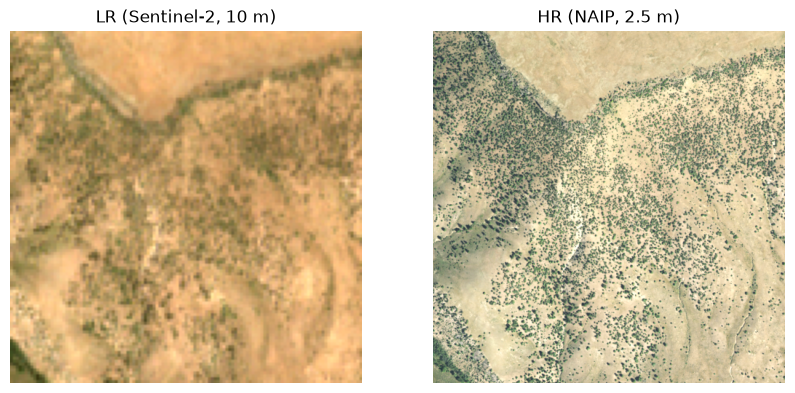

In [9]:
def show_rgb(img, title=""):
    # img: (bands, H, W), use bands 0,1,2 as R,G,B and stretch to 0-1 for display
    rgb = img[:3].transpose(1, 2, 0).astype(float)
    rgb = rgb / np.percentile(rgb, 99)
    plt.imshow(np.clip(rgb, 0, 1))
    plt.title(title)
    plt.axis("off")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); show_rgb(lr, "LR (Sentinel-2, 10 m)")
plt.subplot(1, 2, 2); show_rgb(hr, "HR (NAIP, 2.5 m)")
plt.show()

In [10]:
with open(folder + "/metadata.json") as f:
    meta = json.load(f)

for key, value in meta.items():
    print(f"{key:25s} {value}")

roi_id                    ROI_00002
s2_id                     S2A_MSIL2A_20190909T174911_N0213_R141_T13SCB_20190909T235808
s2_date                   2019-09-09
s2_mean_solar_azimuth     153.227490997
s2_mean_solar_zenith      35.0285338826
naip_id                   m_3710663_nw_13_060_20190909
naip_date                 2019-09-09
proj:epsg                 32613
proj:geometry             POLYGON ((391740 4106030, 391740 4107240, 390530 4107240, 390530 4106030, 391740 4106030))
proj:transform            2.5, 0.0, 390530.0, 0.0, -2.5, 4107240.0, 0.0, 0.0, 1.0
QA1                       0.65395188331604
QA2                       1.8174691200256348
d_sim_to_real             None


Useful fields:
- `s2_id`: Sentinel-2 product. The part like `T13SCB` is the **MGRS tile** (a ~110 km square on Earth)
- `s2_date` / `naip_date`: both images are from the same day or 1 day apart → real pairs, not simulated
- `roi_id`: location id. Note folder `ROI_0000` has `roi_id` `ROI_00002`, so folder name ≠ roi_id
- `proj:epsg`: coordinate system (UTM zone)

Let's put the metadata of all pairs in a table.

In [12]:
rows = []
for name in folders:
    with open(os.path.join(data_dir, name, "metadata.json")) as f:
        m = json.load(f)
    transform = [float(v) for v in m["proj:transform"].split(",")]
    rows.append({
        "folder": name,
        "roi_id": m["roi_id"],
        "mgrs_tile": m["s2_id"].split("_")[5],
        "epsg": m["proj:epsg"],
        "x_min": transform[2],     # left edge (metres)
        "y_max": transform[5],     # top edge (metres)
        "s2_date": m["s2_date"],
        "naip_date": m["naip_date"],
        "qa1": m["QA1"],
        "qa2": m["QA2"],
    })

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(2851, 10)


,folder,roi_id,mgrs_tile,epsg,x_min,y_max,s2_date,naip_date,qa1,qa2
0,ROI_0000,ROI_00002,T13SCB,32613,390530.0,4107240.0,2019-09-09,2019-09-09,0.653952,1.817469
1,ROI_0001,ROI_00004,T10TFQ,32610,657140.0,4960540.0,2020-07-03,2020-07-03,0.343426,0.880230
2,ROI_0002,ROI_00006,T11TQK,32611,793610.0,4935100.0,2021-09-17,2021-09-17,0.215198,0.695022
3,ROI_0003,ROI_00006,T11TQK,32611,793610.0,4933900.0,2021-09-17,2021-09-17,0.294030,0.960194
4,ROI_0004,ROI_00007,T13TEL,32613,600620.0,5038230.0,2021-08-29,2021-08-30,0.543239,0.935708


In [13]:
print("unique locations (roi_id):", df["roi_id"].nunique(), "out of", len(df), "pairs")
print("MGRS tiles:", df["mgrs_tile"].nunique())
print("UTM zones:", df["epsg"].nunique())
print("same date:", (df["s2_date"] == df["naip_date"]).sum(), "| different date:", (df["s2_date"] != df["naip_date"]).sum())
print()
print(df["s2_date"].str[:4].value_counts().sort_index())

unique locations (roi_id): 2323 out of 2851 pairs
MGRS tiles: 626
UTM zones: 10
same date: 1664 | different date: 1187

s2_date
2019    1004
2020     879
2021     952
2022      16
Name: count, dtype: int64


**Only 2323 unique locations for 2851 pairs** → some places appear more than once (different dates). This matters for the split later: the same place must not be in both train and test.

## 2. Check that all files are OK

Loop over every pair and count anything unexpected.

In [16]:
problems = []
negative_lr = []

for i, name in enumerate(folders):
    if i % 500 == 0:
        print("checking", i, "/", len(folders))
    with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f_lr, rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f_hr:
        lr = f_lr.read()
        if lr.shape != (4, 121, 121) or f_hr.shape != (484, 484) or f_hr.count != 4:
            problems.append((name, "wrong shape"))
        if f_lr.crs != f_hr.crs:
            problems.append((name, "different CRS"))
        if f_lr.bounds != f_hr.bounds:
            problems.append((name, "different bounds"))
        if f_hr.res != (2.5, 2.5) or f_lr.res != (10.0, 10.0):
            problems.append((name, "wrong pixel size"))
        if (lr == f_lr.nodata).any():
            problems.append((name, "nodata pixels"))
        if (lr < 0).any():
            negative_lr.append((name, (lr < 0).sum(), lr.min()))

print("problems found:", len(problems))
print(problems[:10])
print("tiles with negative LR values:", negative_lr)

checking 0 / 2851
checking 500 / 2851
checking 1000 / 2851
checking 1500 / 2851
checking 2000 / 2851
checking 2500 / 2851
problems found: 0
[]
tiles with negative LR values: [('ROI_0282', np.int64(484), np.int32(-99)), ('ROI_0879', np.int64(968), np.int32(-99)), ('ROI_1312', np.int64(6), np.int32(-99)), ('ROI_2338', np.int64(946), np.int32(-99))]


All files are fine. Only 4 tiles have a few slightly negative values (down to -99, i.e. -0.0099 reflectance). That happens in Sentinel-2 L2A data over very dark areas. We will just **clip to 0** (SEN2SR also clamps its output at 0).

## 3. Band order

NAIP is always R, G, B, NIR. SEN2SR wants B04, B03, B02, B08 = also R, G, B, NIR. Is our LR in the same order?

Test 1: shrink HR to 10 m and check which HR band each LR band matches best (correlation).

In [17]:
def to_10m(hr):
    # average every 4x4 block of HR pixels -> 121 x 121
    return block_reduce(hr, (1, 4, 4), np.mean)

corr = np.zeros((4, 4))
sample = folders[::10]     # every 10th pair is enough

for name in sample:
    with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
        lr = f.read().astype(float)
    with rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f:
        hr = f.read().astype(float)
    hr_small = to_10m(hr)
    for i in range(4):
        for j in range(4):
            corr[i, j] += np.corrcoef(lr[i].ravel(), hr_small[j].ravel())[0, 1]

corr = corr / len(sample)
print(pd.DataFrame(corr, index=["LR band 1", "LR band 2", "LR band 3", "LR band 4"],
                   columns=["HR R", "HR G", "HR B", "HR NIR"]).round(2))

           HR R  HR G  HR B  HR NIR
LR band 1  0.86  0.81  0.82    0.26
LR band 2  0.81  0.85  0.82    0.35
LR band 3  0.79  0.81  0.86    0.23
LR band 4  0.25  0.35  0.22    0.82


The diagonal is the highest in every row, so LR band i matches HR band i. NIR is clearly different from the visible bands.

Test 2: vegetation has a known signature: **green > red** (that's why plants look green), **blue is low**, and **NIR is very high**. Take pixels with high NDVI = (NIR - R) / (NIR + R), i.e. vegetation:

In [18]:
veg = []
for name in sample:
    with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
        lr = f.read().astype(float) / 10000
    ndvi = (lr[3] - lr[0]) / (lr[3] + lr[0] + 1e-9)
    if (ndvi > 0.6).sum() > 200:
        veg.append([lr[b][ndvi > 0.6].mean() for b in range(4)])

veg = np.array(veg)
print("tiles with vegetation:", len(veg))
print("mean reflectance R, G, B, NIR:", veg.mean(axis=0).round(3))
print("green > red in", round((veg[:, 1] > veg[:, 0]).mean() * 100), "% of tiles")
print("blue < green in", round((veg[:, 2] < veg[:, 1]).mean() * 100), "% of tiles")

tiles with vegetation: 149
mean reflectance R, G, B, NIR: [0.043 0.058 0.032 0.332]
green > red in 98 % of tiles
blue < green in 100 % of tiles


Both tests agree → band order is **R, G, B, NIR** = exactly what SEN2SR expects. No reordering needed.

## 4. Convert HR to reflectance

HR is 0-255, LR is reflectance. To compare the model output with HR we need HR in reflectance too.

Idea: for one pair, shrink HR to 10 m and plot it against LR, pixel by pixel. If the relationship is a straight line, we can fit `LR = a * HR + b` and apply it to the full HR.

LR: (4, 121, 121) | HR shrunk: (4, 121, 121)


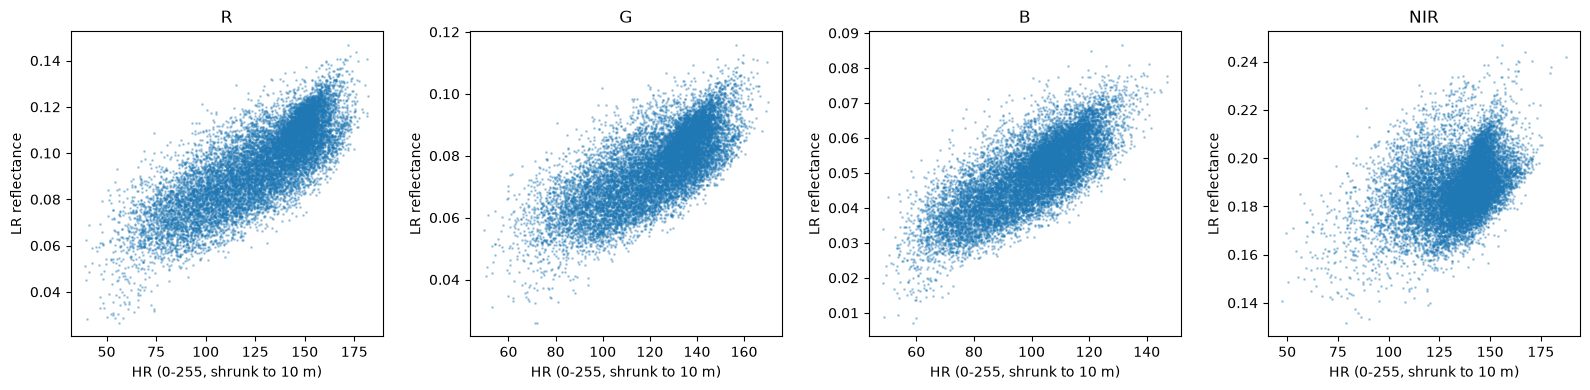

In [19]:
name = folders[0]
with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
    lr = np.clip(f.read().astype(float) / 10000, 0, None)
with rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f:
    hr = f.read().astype(float)

hr_small = to_10m(hr)
print("LR:", lr.shape, "| HR shrunk:", hr_small.shape)

band_names = ["R", "G", "B", "NIR"]
plt.figure(figsize=(16, 4))
for b in range(4):
    plt.subplot(1, 4, b + 1)
    plt.scatter(hr_small[b].ravel(), lr[b].ravel(), s=1, alpha=0.3)
    plt.xlabel("HR (0-255, shrunk to 10 m)")
    plt.ylabel("LR reflectance")
    plt.title(band_names[b])
plt.tight_layout()
plt.show()

Roughly a straight line for every band, but with a lot of spread. Part of the spread is because Sentinel-2 images are a bit **blurry** (the satellite's optics blur the image), while a plain 4x4 average is sharp.

Try blurring HR a little before shrinking it and see if the fit gets better. R² tells how good the line fits (1 = perfect).

In [20]:
def fit_line(x, y):
    a, b = np.polyfit(x.ravel(), y.ravel(), 1)        # y = a*x + b
    r2 = np.corrcoef(x.ravel(), y.ravel())[0, 1] ** 2
    return a, b, r2

for sigma in [0, 1, 2, 3, 4]:
    r2_all = []
    for name in sample:
        with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
            lr = np.clip(f.read().astype(float) / 10000, 0, None)
        with rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f:
            hr = f.read().astype(float)
        if sigma > 0:
            hr = gaussian_filter(hr, sigma=(0, sigma, sigma))   # blur each band, not across bands
        hr_small = to_10m(hr)
        r2_all.append([fit_line(hr_small[b], lr[b])[2] for b in range(4)])
    print(f"blur sigma {sigma}: median R2 per band = {np.median(r2_all, axis=0).round(3)}")

blur sigma 0: median R2 per band = [0.803 0.79  0.805 0.755]
blur sigma 1: median R2 per band = [0.828 0.814 0.835 0.79 ]
blur sigma 2: median R2 per band = [0.846 0.833 0.854 0.825]
blur sigma 3: median R2 per band = [0.841 0.827 0.841 0.83 ]
blur sigma 4: median R2 per band = [0.823 0.801 0.813 0.816]


**sigma = 2** (HR pixels) gives the best fit, so we use that.

Important: the blur is only used to **find** a and b. The final HR keeps its full sharpness: `HR_reflectance = a * HR + b`.

In [21]:
blur_sigma = 2

def fit_pair(lr, hr):
    # returns a, b, r2 for each of the 4 bands
    hr_small = to_10m(gaussian_filter(hr, sigma=(0, blur_sigma, blur_sigma)))
    return [fit_line(hr_small[b], lr[b]) for b in range(4)]

name = folders[0]
with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
    lr = np.clip(f.read().astype(float) / 10000, 0, None)
with rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f:
    hr = f.read().astype(float)

fits = fit_pair(lr, hr)
for b in range(4):
    a, c, r2 = fits[b]
    print(f"{band_names[b]:4s} a = {a:.6f}  b = {c:.4f}  R2 = {r2:.3f}")

hr_refl = np.stack([fits[b][0] * hr[b] + fits[b][1] for b in range(4)])
hr_refl = np.clip(hr_refl, 0, None)
print("\nHR before:", hr.min(), "-", hr.max(), "| after:", hr_refl.min().round(4), "-", hr_refl.max().round(4))
print("mean per band  LR:", lr.mean(axis=(1, 2)).round(4))
print("mean per band  HR:", hr_refl.mean(axis=(1, 2)).round(4))

R    a = 0.000621  b = 0.0166  R2 = 0.687
G    a = 0.000499  b = 0.0154  R2 = 0.577
B    a = 0.000565  b = -0.0067  R2 = 0.624
NIR  a = 0.000334  b = 0.1429  R2 = 0.147

HR before: 22.0 - 214.0 | after: 0.0165 - 0.2145
mean per band  LR: [0.0958 0.0765 0.0496 0.1878]
mean per band  HR: [0.0958 0.0765 0.0496 0.1878]


The HR band means now match the LR → same unit. Visually (LR and converted HR use the **same** colour stretch now):

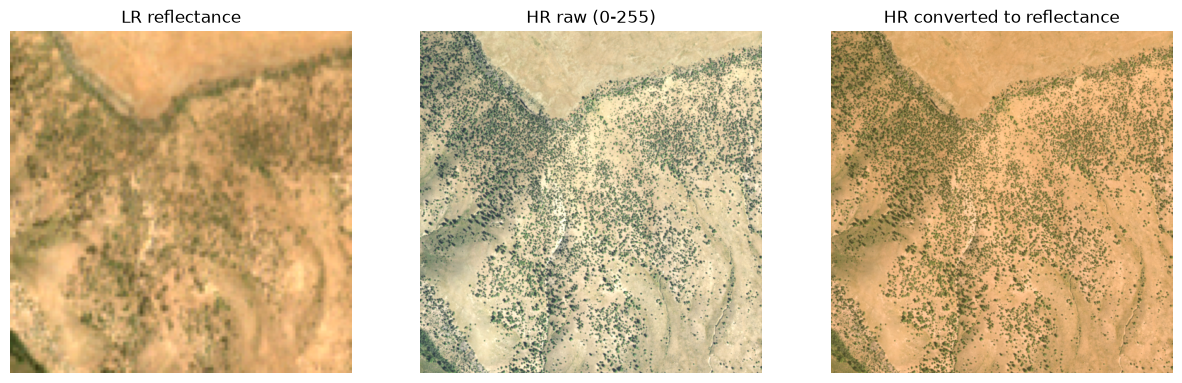

In [22]:
def show_refl(img, title, stretch):
    plt.imshow(np.clip(img[:3].transpose(1, 2, 0) / stretch, 0, 1))
    plt.title(title)
    plt.axis("off")

stretch = np.percentile(lr[:3], 99)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show_refl(lr, "LR reflectance", stretch)
plt.subplot(1, 3, 2); show_rgb(hr, "HR raw (0-255)")
plt.subplot(1, 3, 3); show_refl(hr_refl, "HR converted to reflectance", stretch)
plt.show()

Works for one pair. Now do the same for **all** pairs and save a, b and R² for each band. Also save a few simple numbers about each image (brightness, vegetation, contrast) to check later that the splits look similar.

In [23]:
results = []

for i, name in enumerate(folders):
    if i % 500 == 0:
        print("fitting", i, "/", len(folders))
    with rasterio.open(os.path.join(data_dir, name, "lr.tif")) as f:
        lr = np.clip(f.read().astype(float) / 10000, 0, None)
    with rasterio.open(os.path.join(data_dir, name, "hr.tif")) as f:
        hr = f.read().astype(float)

    row = {"folder": name}
    fits = fit_pair(lr, hr)
    for b, band in enumerate(band_names):
        row["a_" + band], row["b_" + band], row["r2_" + band] = fits[b]

    ndvi = (lr[3] - lr[0]) / (lr[3] + lr[0] + 1e-9)
    row["brightness"] = lr[:3].mean()
    row["ndvi"] = ndvi.mean()
    row["contrast"] = lr.std(axis=(1, 2)).mean()
    results.append(row)

fit_df = pd.DataFrame(results)
df = df.merge(fit_df, on="folder")
print(df.shape)
df[["folder", "a_R", "b_R", "r2_R", "r2_G", "r2_B", "r2_NIR"]].head()

fitting 0 / 2851
fitting 500 / 2851
fitting 1000 / 2851
fitting 1500 / 2851
fitting 2000 / 2851
fitting 2500 / 2851
(2851, 25)


,folder,a_R,b_R,r2_R,r2_G,r2_B,r2_NIR
0,ROI_0000,0.000621,0.016609,0.686565,0.576788,0.624093,0.146776
1,ROI_0001,0.000645,0.057457,0.327246,0.215645,0.278682,0.111835
2,ROI_0002,0.001294,-0.017390,0.853520,0.837423,0.835436,0.776663
3,ROI_0003,0.001103,0.001606,0.926995,0.907516,0.928213,0.293496
4,ROI_0004,0.001886,-0.129538,0.846641,0.844790,0.847104,0.829301


median R2 per band:
r2_R      0.844
r2_G      0.832
r2_B      0.852
r2_NIR    0.808
dtype: float64


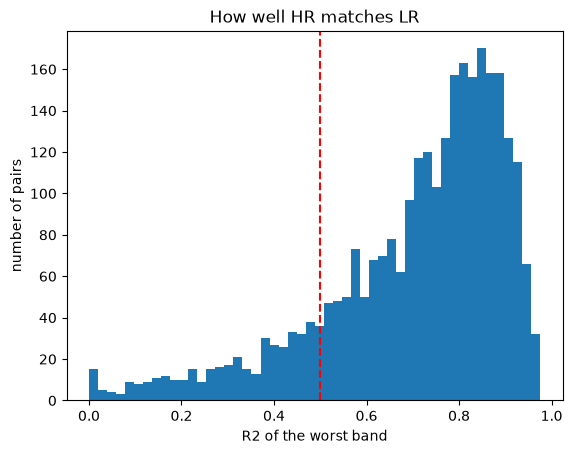

In [24]:
r2_cols = ["r2_R", "r2_G", "r2_B", "r2_NIR"]
df["r2_min"] = df[r2_cols].min(axis=1)      # worst band of each pair

print("median R2 per band:")
print(df[r2_cols].median().round(3))

plt.hist(df["r2_min"], bins=50)
plt.axvline(0.5, color="red", linestyle="--")
plt.xlabel("R2 of the worst band")
plt.ylabel("number of pairs")
plt.title("How well HR matches LR")
plt.show()

Most pairs fit well, but there is a tail of bad fits. Some even have a **negative slope** (a ≤ 0), meaning HR gets darker where LR gets brighter - clearly not usable.

Let's look at the worst ones before deciding what to do.

In [25]:
slope_cols = ["a_R", "a_G", "a_B", "a_NIR"]
df["negative_slope"] = (df[slope_cols] <= 0).any(axis=1)
df["low_fit"] = (df["r2_min"] < 0.5) | df["negative_slope"]

print("pairs with negative slope:", df["negative_slope"].sum())
print("pairs marked low_fit:", df["low_fit"].sum(), f"({df['low_fit'].mean() * 100:.1f}%)")

pairs with negative slope: 7
pairs marked low_fit: 422 (14.8%)


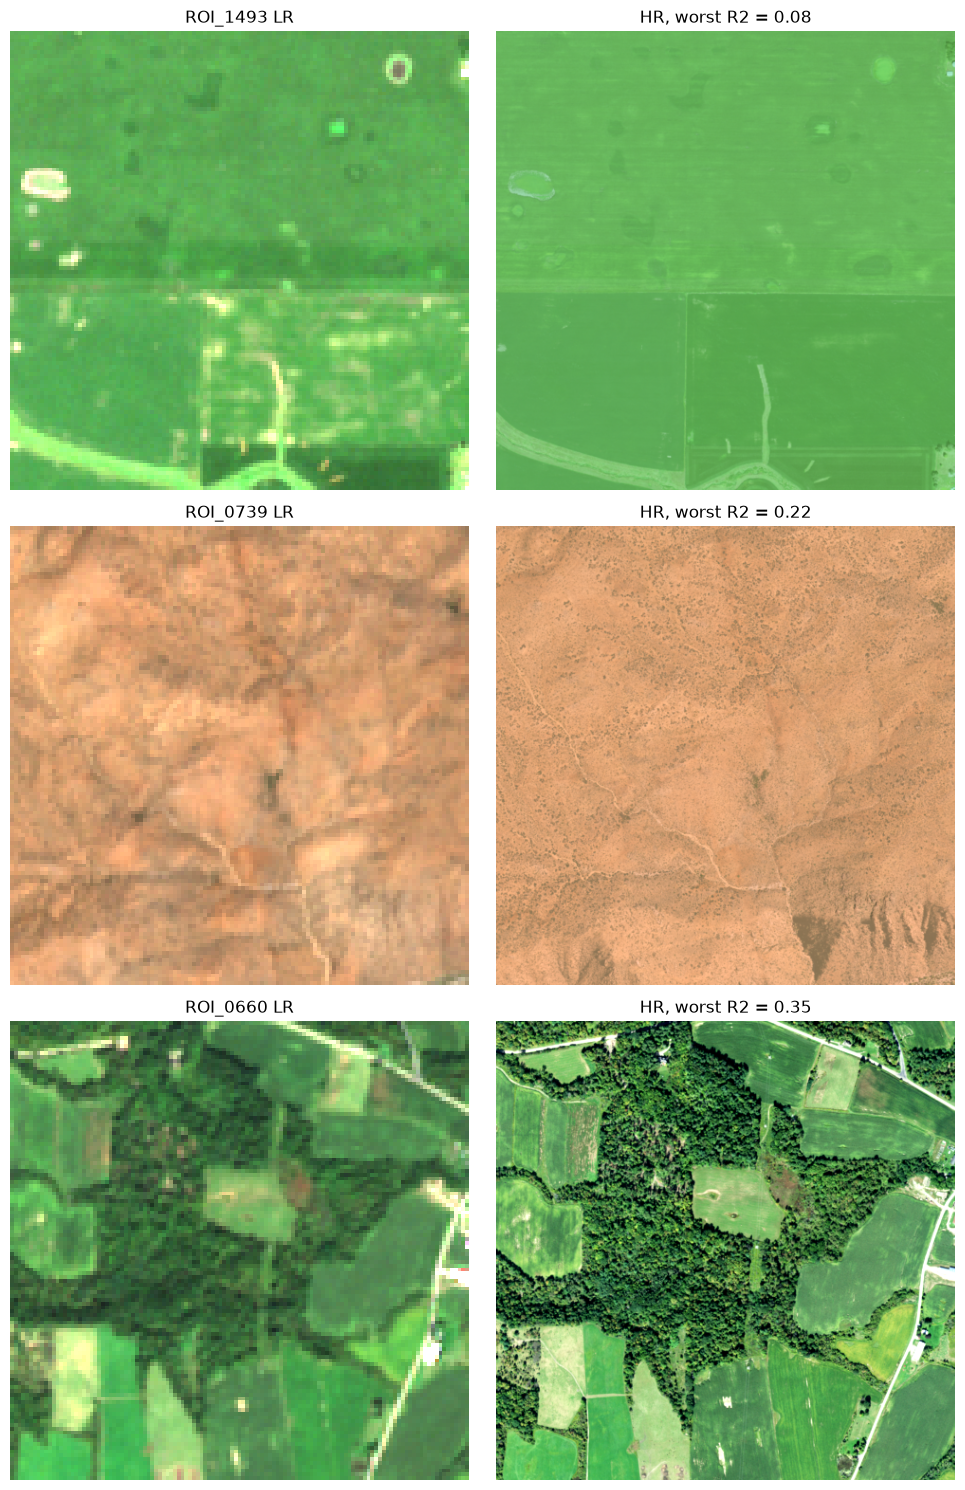

In [26]:
def load_pair(row):
    # LR and HR as reflectance (float32), using the a and b of this pair
    with rasterio.open(os.path.join(data_dir, row["folder"], "lr.tif")) as f:
        lr = np.clip(f.read().astype(np.float32) / 10000, 0, None)
    with rasterio.open(os.path.join(data_dir, row["folder"], "hr.tif")) as f:
        hr = f.read().astype(np.float32)
    for b, band in enumerate(band_names):
        hr[b] = row["a_" + band] * hr[b] + row["b_" + band]
    hr = np.clip(hr, 0, None)
    return lr, hr

worst = df.sort_values("r2_min").iloc[[30, 100, 200]]   # some bad (not the very worst) examples
plt.figure(figsize=(10, 15))
for i, (_, row) in enumerate(worst.iterrows()):
    lr, hr = load_pair(row)
    stretch = np.percentile(lr[:3], 99)
    plt.subplot(3, 2, 2 * i + 1); show_refl(lr, f"{row['folder']} LR", stretch)
    plt.subplot(3, 2, 2 * i + 2); show_refl(hr, f"HR, worst R2 = {row['r2_min']:.2f}", stretch)
plt.tight_layout()
plt.show()

In [27]:
print(worst[["folder", "r2_R", "r2_G", "r2_B", "r2_NIR", "contrast", "s2_date", "naip_date"]].round(3))
print()
low = df[df["low_fit"]]
good = df[~df["low_fit"]]
print("median contrast   low_fit:", round(low["contrast"].median(), 4), "| others:", round(good["contrast"].median(), 4))
print("low_fit share     same day:", round(df[df["s2_date"] == df["naip_date"]]["low_fit"].mean(), 3),
      "| 1 day apart:", round(df[df["s2_date"] != df["naip_date"]]["low_fit"].mean(), 3))
print("worst band is NIR in", round((low[r2_cols].idxmin(axis=1) == "r2_NIR").mean() * 100), "% of low_fit pairs")

        folder   r2_R   r2_G   r2_B  r2_NIR  contrast     s2_date   naip_date
1493  ROI_1493  0.082  0.092  0.156   0.090     0.020  2019-07-29  2019-07-29
739   ROI_0739  0.332  0.253  0.275   0.220     0.018  2019-06-22  2019-06-23
660   ROI_0660  0.408  0.440  0.345   0.722     0.042  2019-09-18  2019-09-18

median contrast   low_fit: 0.0198 | others: 0.0255
low_fit share     same day: 0.129 | 1 day apart: 0.175
worst band is NIR in 61 % of low_fit pairs


The reasons are mixed:
- **ROI_1493**: the LR has bright spots that are not in the HR, although both are from the same day → probably small clouds / haze in the Sentinel-2 image. A real mismatch.
- **ROI_0739**: very uniform dry land. There is little variation, so a straight line can't explain much and R² is low even though the images look alike.
- **ROI_0660**: looks alike, but the visible bands only fit ~0.35-0.45. Sharp edges (forest, fields, roads) don't line up perfectly at 10 m, and NAIP shows shadows differently.

Overall, low_fit pairs have lower contrast, are a bit more common when the images are 1 day apart, and NIR is most often the worst band.

Decision: **don't delete** these pairs, just keep the `low_fit` flag. Later we report results on all test pairs **and** on the good ones only.

## 5. Split into train / val / test

We can't split pairs randomly:
- the same location appears on different dates
- many images are next to each other (same MGRS tile)

If one of them is in train and its neighbour in test, the model has basically seen the test image → the score looks better than it really is (**data leakage**).

Solution: make **groups** and put each whole group into one split.
- start with group = MGRS tile
- if the same `roi_id` (location) is in two different groups, merge those groups

In [28]:
df["group"] = df["mgrs_tile"]

changed = True
while changed:
    changed = False
    for roi, rows in df.groupby("roi_id"):
        groups = rows["group"].unique()
        if len(groups) > 1:
            df.loc[df["group"].isin(groups), "group"] = groups[0]   # merge them into one group
            changed = True

print("number of groups:", df["group"].nunique())
print("biggest group:", df["group"].value_counts().max(), "pairs")

number of groups: 614
biggest group: 27 pairs


Now assign groups to splits: shuffle the groups, fill train until 70%, then val until 85%, the rest is test.

In [29]:
def make_split(df, seed):
    groups = sorted(df["group"].unique())    # plain python list, sorted so the result only depends on the seed
    rng = np.random.default_rng(seed)
    rng.shuffle(groups)
    sizes = df["group"].value_counts()

    split_of_group = {}
    count = 0
    for g in groups:
        if count < 0.70 * len(df):
            split_of_group[g] = "train"
        elif count < 0.85 * len(df):
            split_of_group[g] = "val"
        else:
            split_of_group[g] = "test"
        count += sizes[g]
    return df["group"].map(split_of_group)

split = make_split(df, seed=0)
print(split.value_counts())

group
train    1997
val       433
test      421
Name: count, dtype: int64


Problem: with only ~600 groups, one random shuffle can give a test set that looks different from train (e.g. much greener or brighter). Then the test score would not represent the whole dataset.

How to measure "looks different"? Comparing averages is not enough: two splits can have the same average brightness but a different spread. The **KS test** (`scipy.stats.ks_2samp`) compares the whole distribution of two samples. Its statistic is 0 for identical distributions and 1 for completely different ones. Score of a split = the **worst** KS statistic over a few image properties, train vs val and train vs test.

In [30]:
features = ["brightness", "ndvi", "contrast", "r2_min", "qa1"]

def imbalance(df, split):
    worst = 0
    for feat in features:
        for s in ["val", "test"]:
            stat = ks_2samp(df.loc[split == "train", feat], df.loc[split == s, feat]).statistic
            worst = max(worst, stat)
    return worst

for seed in range(5):
    print("seed", seed, "imbalance:", round(imbalance(df, make_split(df, seed)), 3))

seed 0 imbalance: 0.091
seed 1 imbalance: 0.115
seed 2 imbalance: 0.084
seed 3 imbalance: 0.122
seed 4 imbalance: 0.083


Big differences between seeds. So we try 200 seeds and keep the most balanced one. (We only look at image properties here, never at model results, so this is fair.)

In [31]:
scores = []
for seed in range(200):
    scores.append(imbalance(df, make_split(df, seed)))

best_seed = int(np.argmin(scores))
print("best seed:", best_seed, "| imbalance:", round(scores[best_seed], 3))
print("median imbalance over all seeds:", round(np.median(scores), 3))

df["split"] = make_split(df, best_seed)
print(df["split"].value_counts())
print((df["split"].value_counts(normalize=True) * 100).round(1))

best seed: 97 | imbalance: 0.066
median imbalance over all seeds: 0.116
split
train    1999
val       433
test      419
Name: count, dtype: int64
split
train    70.1
val      15.2
test     14.7
Name: proportion, dtype: float64


In [32]:
# compare the splits: averages, and KS p-value vs train (p > 0.05 = no clear difference)
print(df.groupby("split")[features + ["qa2", "low_fit"]].mean().loc[["train", "val", "test"]].round(3))
print()
for feat in features + ["qa2"]:
    p_val = ks_2samp(df.loc[df["split"] == "train", feat], df.loc[df["split"] == "val", feat]).pvalue
    p_test = ks_2samp(df.loc[df["split"] == "train", feat], df.loc[df["split"] == "test", feat]).pvalue
    print(f"{feat:12s} KS p-value  train vs val: {p_val:.3f}   train vs test: {p_test:.3f}")

       brightness   ndvi  contrast  r2_min    qa1    qa2  low_fit
split                                                            
train       0.104  0.390     0.027   0.706  0.666  1.166    0.146
val         0.106  0.402     0.027   0.711  0.659  1.137    0.150
test        0.101  0.400     0.025   0.695  0.677  1.151    0.158

brightness   KS p-value  train vs val: 0.103   train vs test: 0.275
ndvi         KS p-value  train vs val: 0.106   train vs test: 0.245
contrast     KS p-value  train vs val: 0.926   train vs test: 0.089
r2_min       KS p-value  train vs val: 0.378   train vs test: 0.264
qa1          KS p-value  train vs val: 0.366   train vs test: 0.203
qa2          KS p-value  train vs val: 0.103   train vs test: 0.605


`qa2` was **not** used to choose the split, so it is a fair extra check that the splits are really similar.

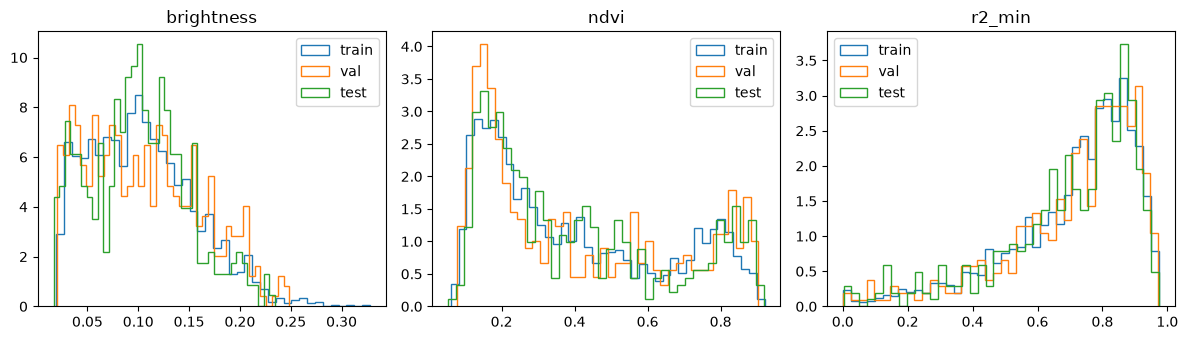

In [33]:
plt.figure(figsize=(12, 3.5))
for i, feat in enumerate(["brightness", "ndvi", "r2_min"]):
    plt.subplot(1, 3, i + 1)
    for s in ["train", "val", "test"]:
        plt.hist(df.loc[df["split"] == s, feat], bins=40, density=True, histtype="step", label=s)
    plt.title(feat)
    plt.legend()
plt.tight_layout()
plt.show()

The three splits now look very similar. Last check for leakage: are any two images from **different** splits touching or overlapping on the ground? Two tiles (1210 m wide) touch if their corners are less than 1210 m apart in both x and y (only meaningful inside the same UTM zone).

In [34]:
leaks = 0
for epsg, zone in df.groupby("epsg"):
    x = zone["x_min"].values
    y = zone["y_max"].values
    s = zone["split"].values
    for i in range(len(zone)):
        near = (np.abs(x - x[i]) <= 1210) & (np.abs(y - y[i]) <= 1210)
        leaks += (near & (s != s[i])).sum()

print("touching pairs in different splits:", leaks)
print("roi_id in more than one split:", (df.groupby("roi_id")["split"].nunique() > 1).sum())
print("MGRS tile in more than one split:", (df.groupby("mgrs_tile")["split"].nunique() > 1).sum())

touching pairs in different splits: 0
roi_id in more than one split: 0
MGRS tile in more than one split: 0


## 6. Save

In [35]:
df.to_csv("dataset_index.csv", index=False)
print("saved dataset_index.csv:", df.shape)
print(list(df.columns))

saved dataset_index.csv: (2851, 30)
['folder', 'roi_id', 'mgrs_tile', 'epsg', 'x_min', 'y_max', 's2_date', 'naip_date', 'qa1', 'qa2', 'a_R', 'b_R', 'r2_R', 'a_G', 'b_G', 'r2_G', 'a_B', 'b_B', 'r2_B', 'a_NIR', 'b_NIR', 'r2_NIR', 'brightness', 'ndvi', 'contrast', 'r2_min', 'negative_slope', 'low_fit', 'group', 'split']


Every later phase will:
1. read `dataset_index.csv`
2. pick the rows of the split it needs
3. use `load_pair(row)` (defined above) to get LR and HR as reflectance

Quick test of that workflow:

val pairs: 433
lr: (4, 121, 121) float32 0.0163 0.3906
hr: (4, 484, 484) float32 0.0 0.37525916


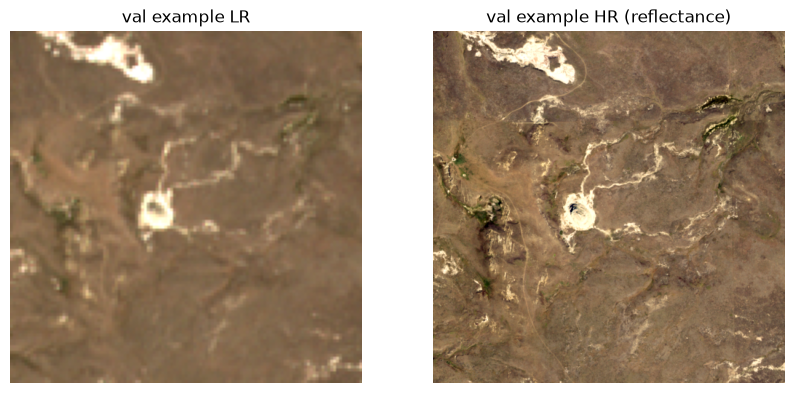

In [36]:
index = pd.read_csv("dataset_index.csv")
val_rows = index[index["split"] == "val"]
print("val pairs:", len(val_rows))

lr, hr = load_pair(val_rows.iloc[0])
print("lr:", lr.shape, lr.dtype, lr.min(), lr.max())
print("hr:", hr.shape, hr.dtype, hr.min(), hr.max())

stretch = np.percentile(lr[:3], 99)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); show_refl(lr, "val example LR", stretch)
plt.subplot(1, 2, 2); show_refl(hr, "val example HR (reflectance)", stretch)
plt.show()

## Quick checks

In [37]:
assert len(index) == 2851
assert index["folder"].is_unique
assert len(problems) == 0
assert leaks == 0
assert (index.groupby("roi_id")["split"].nunique() == 1).all()
assert (index.groupby("group")["split"].nunique() == 1).all()
assert abs((index["split"] == "test").mean() - 0.15) < 0.02
assert index.loc[index["negative_slope"], "low_fit"].all()
for feat in features + ["qa2"]:
    for s in ["val", "test"]:
        assert ks_2samp(index.loc[index["split"] == "train", feat], index.loc[index["split"] == s, feat]).pvalue > 0.05, (feat, s)

for _, row in index.sample(20, random_state=0).iterrows():
    lr, hr = load_pair(row)
    assert lr.shape == (4, 121, 121) and hr.shape == (4, 484, 484)
    assert lr.min() >= 0 and hr.min() >= 0

print("all checks passed")

all checks passed


## Summary

- **2851 pairs**, all files fine: LR 4 x 121 x 121 (10 m), HR 4 x 484 x 484 (2.5 m), same area and coordinate system.
- Only 2323 unique locations → some places appear on several dates.
- 4 tiles have tiny negative LR values → clipped to 0.
- **Band order is R, G, B, NIR** (checked two ways) = what SEN2SR expects.
- **HR → reflectance:** for each pair and band, fit `LR = a * HR + b` (HR blurred with sigma = 2 and shrunk to 10 m only for the fit). After this, HR and LR are in the same unit.
- Some pairs fit badly (mostly uniform scenes, some clouds / changes) → flagged as `low_fit`, not deleted.
- **Split by groups** (same MGRS tile or same location stay together), most balanced of 200 shuffles → ~70 / 15 / 15, no leakage.
- Saved in `dataset_index.csv`. The **test** split will not be touched until the final evaluation.